# Telco Customer Churn — EDA Report

**Week 2 · Day 6 · Mini-project**  
Dataset: `telecom_churn.csv` — 3,500 customers × 23 columns (synthetic, generated with `generate_data.py`, seed 42).

> **One-sentence summary.** In this sample, churn is the *majority* outcome (55.6%); the strongest
> legitimate drivers are contract type, tenure and support calls, while four "too good to be true"
> columns turn out to be recorded *after* the customer left and must be removed before modelling.

**Structure:** Context → Data → Cleaning → Insights → Next steps.

---

## 1. Context

### The business problem

A telecom operator wants to know **who is about to leave** so it can offer retention deals.
A missed churner costs roughly **$500** in lost lifetime value; a wasted retention offer costs
about **$100**. The company therefore needs a model that ranks customers by churn risk, not one
that merely labels them.

### The questions this EDA must answer

1. How common is churn, and is this sample representative of the real business?
2. Which customer behaviours and contract choices are associated with churn?
3. Which columns are safe to use as features — and which ones secretly contain the answer?
4. What should the modelling team do next?

### Who this report is for

A non-technical stakeholder should be able to read the **Insights** section and act on it;
a data scientist should be able to reproduce every number from the code cells.

### Dataset card

| Property | Value |
|---|---|
| Rows × columns | 3,500 × 23 |
| Unit of observation | one customer |
| Target | `churn` — 1 = left, 0 = stayed |
| Churn rate | 55.6% (1,947 / 3,500) |
| Missing values | `tech_support` 60, `total_charges` 45, `customer_service_calls` 35, `cancellation_request` 1,553 |
| Planted data-quality problems | leakage columns, informative missingness, a derived column |
| Source | `generate_data.py` in this folder (same generator as Day 5, `random_state=42`) |

The dataset is synthetic on purpose: it behaves like the classic Kaggle *Telco Customer Churn*
dataset but contains **planted problems** so that data cleaning and leakage checks are not
theoretical. Every number below is computed from the file, not typed by hand.

## 2. Data

### 2.1 Load the file and take a first look

Two files are possible: the local `data/telecom_churn.csv` (created by `python generate_data.py`)
or the Day 5 copy at `../d5/telecom_churn.csv`. The notebook uses whichever exists, so it also
works if you run it from a fresh clone after generating the data.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "axes.titlesize": 12, "axes.titleweight": "bold"})
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 150)

FIG = Path("figures")
FIG.mkdir(exist_ok=True)

candidates = [Path("data/telecom_churn.csv"), Path("../d5/telecom_churn.csv")]
DATA = next((p for p in candidates if p.exists()), None)
assert DATA is not None, (
    "Dataset not found. Run `python generate_data.py` in this folder "
    "(it writes data/telecom_churn.csv)."
)

raw = pd.read_csv(DATA)
print(f"Loaded {raw.shape[0]:,} rows x {raw.shape[1]} columns from {DATA}")
raw.head()

Loaded 3,500 rows x 23 columns from data\telecom_churn.csv


,customer_id,gender,senior_citizen,partner,dependents,tenure_months,phone_service,multiple_lines,internet_service,online_security,tech_support,streaming_tv,contract,paperless_billing,payment_method,monthly_charges,total_charges,customer_service_calls,satisfaction_score,cancellation_request,last_interaction_status,churn_risk_post_exit_code,churn
0,CUST-10000,Male,0,Yes,Yes,6,Yes,Yes,Fiber optic,Yes,No,No,Two year,No,Credit card (automatic),93.88,590.03,6.0,1,Recorded,Retention Declined,999,1
1,CUST-10001,Female,0,Yes,Yes,7,Yes,No,DSL,No,Yes,Yes,Two year,Yes,Credit card (automatic),73.78,578.74,3.0,2,Recorded,Account Closed,999,1
2,CUST-10002,Female,1,No,No,60,Yes,No,Fiber optic,No,No,No,Month-to-month,No,Mailed check,74.06,4435.36,4.0,2,Recorded,Account Closed,999,1
3,CUST-10003,Female,0,No,No,1,Yes,No,Fiber optic,Yes,Yes,No,Month-to-month,No,Credit card (automatic),88.89,134.84,4.0,1,Recorded,Account Closed,999,1
4,CUST-10004,Male,1,Yes,No,22,Yes,No,Fiber optic,No,No,No,Two year,Yes,Credit card (automatic),81.31,1725.80,3.0,1,Recorded,Retention Declined,999,1


`head()` is not analysis — it is a sanity check. Look for: sensible column names, values that
match their meaning, and obvious placeholder values such as `999`, `"unknown"` or empty strings.

### 2.2 Shape, types and uniqueness

Three questions, one table:

* **How much data?** 3,500 rows — enough for stable rates, small enough to iterate quickly.
* **What type is each column?** Types decide which operations are legal. A number stored as text
  cannot be averaged; a category stored as an integer can silently be treated as continuous.
* **Is the identifier unique?** If `customer_id` repeats, "3,500 customers" is a lie.

In [2]:
overview = pd.DataFrame(
    {
        "value": [
            f"{raw.shape[0]:,}",
            raw.shape[1],
            raw["customer_id"].nunique(),
            int(raw.duplicated().sum()),
            f"{raw['churn'].mean() * 100:.1f}%",
        ]
    },
    index=["rows", "columns", "unique customer_id", "duplicate rows", "churn rate"],
)
overview

,value
rows,"3,500"
columns,23
unique customer_id,3500
duplicate rows,0
churn rate,55.6%


In [3]:
dtype_counts = raw.dtypes.astype(str).value_counts().rename("columns")
print("Column types:")
print(dtype_counts.to_string())
print("\nLow-cardinality columns (<= 7 distinct values):")
low_card = raw.nunique().sort_values()
print(low_card[low_card <= 7].to_string())

Column types:
str        15
int64       5
float64     3

Low-cardinality columns (<= 7 distinct values):
cancellation_request         1
gender                       2
partner                      2
senior_citizen               2
phone_service                2
paperless_billing            2
churn_risk_post_exit_code    2
dependents                   2
churn                        2
streaming_tv                 3
tech_support                 3
online_security              3
internet_service             3
contract                     3
multiple_lines               3
payment_method               4
satisfaction_score           5
last_interaction_status      7


**Reading the result.** `customer_service_calls` is a `float64` even though calls are whole
numbers — because 35 customers have no value and pandas needs a missing-value marker (`NaN`).
That is a hint, not a problem: the missingness itself may be informative.

`customer_id` has 3,500 distinct values for 3,500 rows: it is a key, never a feature.

### 2.3 Missing values

Missing data is a **decision point**, so we quantify it before touching it:

* how many values are missing per column,
* what percentage of rows that is,
* whether the missingness is random or carries meaning.

In [4]:
missing = (
    raw.isna()
    .sum()
    .rename("missing")
    .to_frame()
    .assign(
        pct=lambda d: (d["missing"] / len(raw) * 100).round(2),
        dtype=raw.dtypes.astype(str),
    )
)
missing = missing[missing["missing"] > 0].sort_values("missing", ascending=False)
missing

,missing,pct,dtype
cancellation_request,1553,44.37,str
tech_support,60,1.71,str
total_charges,45,1.29,float64
customer_service_calls,35,1.00,float64


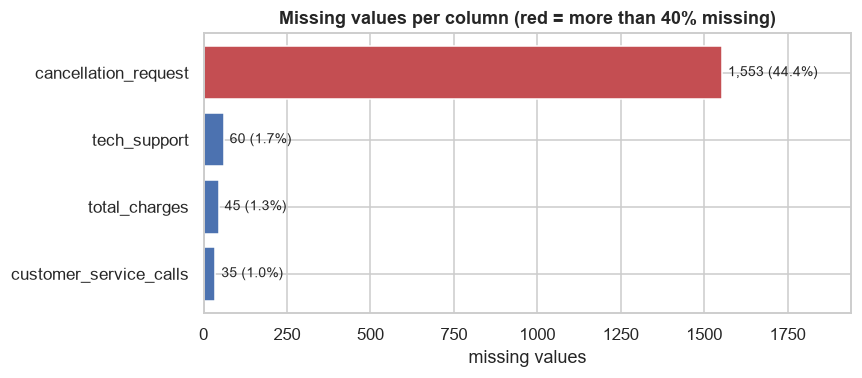

In [5]:
fig, ax = plt.subplots(figsize=(8, 3.6))
colors = ["#C44E52" if pct > 40 else "#4C72B0" for pct in missing["pct"]]
bars = ax.barh(missing.index[::-1], missing["missing"][::-1], color=colors[::-1])
ax.bar_label(bars, labels=[f"{n:,} ({p:.1f}%)" for n, p in zip(missing["missing"][::-1], missing["pct"][::-1])], padding=4, fontsize=9)
ax.set_xlim(0, missing["missing"].max() * 1.25)
ax.set_xlabel("missing values")
ax.set_title("Missing values per column (red = more than 40% missing)")
fig.tight_layout()
fig.savefig(FIG / "02_missingness.png", bbox_inches="tight")
plt.show()

**Reading the result.** Three columns have small, ordinary gaps (1–2% of rows). One column,
`cancellation_request`, is missing for **44.4%** of the rows — that is far too structured to be
random, and it is the first hint that this column is special (we come back to it in Insight 5).

Dropping every row with a missing value (`df.dropna()`) would delete **1,634 of the 3,500 rows
(46.7%)**: most because of `cancellation_request`, plus the overlap from the other columns.
That is the most common beginner mistake in EDA: **never let one column decide the sample size.**

### 2.4 Duplicates and identifiers

Duplicate rows inflate rates and leak information between train and test. With 3,500 rows and one
row per customer, we expect zero duplicates and a unique key — confirm it, do not assume it.

In [6]:
print("Full-row duplicates:", int(raw.duplicated().sum()))
print("Duplicate customer_id :", int(raw["customer_id"].duplicated().sum()))
print("customer_id is unique :", raw["customer_id"].is_unique)

Full-row duplicates: 0
Duplicate customer_id : 0
customer_id is unique : True


### 2.5 Distributions of the numeric columns

`describe()` gives a compact picture: centre (mean/median), spread (std), and the range. A large
gap between mean and median signals skew, which matters later for statistics and for plots.

In [7]:
num_cols = ["tenure_months", "monthly_charges", "total_charges", "customer_service_calls", "satisfaction_score"]
raw[num_cols].describe().round(2)

,tenure_months,monthly_charges,total_charges,customer_service_calls,satisfaction_score
count,3500.00,3500.00,3455.00,3465.0,3500.00
mean,23.12,68.93,1583.23,2.5,2.75
std,20.39,22.21,1558.53,1.9,1.40
min,1.00,18.25,18.00,0.0,1.00
25%,7.00,56.77,404.14,1.0,1.00
50%,17.00,73.55,1062.18,2.0,3.00
75%,33.25,85.62,2259.63,4.0,4.00
max,72.00,110.09,7934.50,11.0,5.00


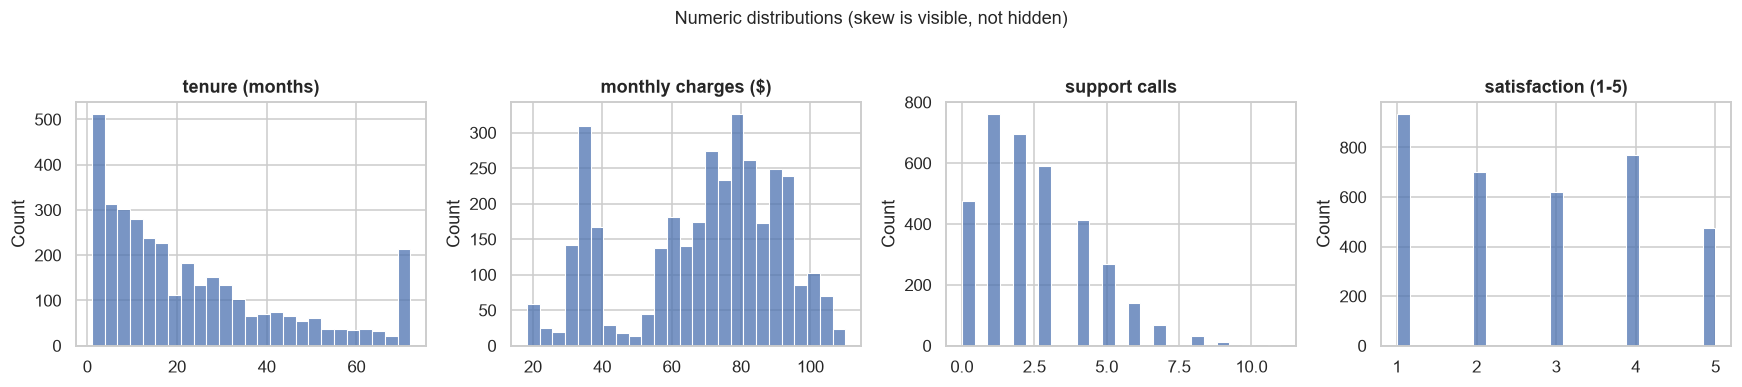

In [8]:
fig, axes = plt.subplots(1, 4, figsize=(16, 3.4))
plot_cols = ["tenure_months", "monthly_charges", "customer_service_calls", "satisfaction_score"]
titles = ["tenure (months)", "monthly charges ($)", "support calls", "satisfaction (1-5)"]
for ax, col, title in zip(axes, plot_cols, titles):
    sns.histplot(raw[col].dropna(), bins=25, ax=ax, color="#4C72B0")
    ax.set_title(title)
    ax.set_xlabel("")
fig.suptitle("Numeric distributions (skew is visible, not hidden)", y=1.03, fontsize=12)
fig.tight_layout()
fig.savefig(FIG / "03_distributions.png", bbox_inches="tight")
plt.show()

**Reading the result.** Tenure is heavily right-skewed: many new customers, few long-tenured ones.
That is typical for subscription businesses and it is why *median* tenure is a better summary than
the mean. Satisfaction is discrete (1–5), not continuous.

---

## 3. Cleaning

Cleaning is not "make the data pretty"; each change below is a decision with a reason and a
consequence. The table is the audit trail a reviewer will ask for.

| # | Decision | Reason | Effect |
|---|---|---|---|
| 1 | Drop `customer_id` | Unique key; no predictive meaning | 23 → 22 columns |
| 2 | Remove 4 leakage columns from the modelling frame | Recorded at/after exit; would give fake 100% accuracy (Insight 5) | 22 → 18 columns |
| 3 | `tech_support` NaN → `"Unknown"` | Missingness is small and random; a separate level is honest | no rows lost |
| 4 | `customer_service_calls` NaN → median + `calls_missing` flag | Small random reporting gap; flag preserves the fact it was missing | no rows lost |
| 5 | `total_charges` NaN → `monthly_charges × tenure_months` + flag | The column is derived from those two columns (r = 0.9995) | no rows lost |
| 6 | Add `tenure_band` and `calls_band` | Human-readable segments for the report | +2 analysis columns |

The leakage columns stay in `raw` for the audit in Insight 5; they are only removed from `df`,
the frame used for analysis and modelling.

In [9]:
LEAKAGE = [
    "cancellation_request",
    "last_interaction_status",
    "churn_risk_post_exit_code",
    "satisfaction_score",
]

df = raw.drop(columns=["customer_id", *LEAKAGE]).copy()

# 1) small, random gap -> explicit category
df["tech_support"] = df["tech_support"].fillna("Unknown")

# 2) keep the missingness signal, then impute with the median
df["calls_missing"] = df["customer_service_calls"].isna().astype(int)
df["customer_service_calls"] = df["customer_service_calls"].fillna(df["customer_service_calls"].median())

# 3) total_charges is (almost exactly) monthly_charges * tenure -> rebuild it
df["total_charges_missing"] = df["total_charges"].isna().astype(int)
df["total_charges"] = df["total_charges"].fillna(df["monthly_charges"] * df["tenure_months"])

# 4) analysis bands (not model features, just readable segments)
df["tenure_band"] = pd.cut(
    df["tenure_months"],
    bins=[0, 12, 24, 36, 48, 60, 72],
    labels=["1-12", "13-24", "25-36", "37-48", "49-60", "61-72"],
)
df["calls_band"] = pd.cut(
    df["customer_service_calls"],
    bins=[-1, 0, 2, 4, 6, 20],
    labels=["0", "1-2", "3-4", "5-6", "7+"],
)

print(f"raw     : {raw.shape[0]:,} rows x {raw.shape[1]} columns")
print(f"cleaned : {df.shape[0]:,} rows x {df.shape[1]} columns")
print(f"missing values left: {int(df.isna().sum().sum())}")
df[["tenure_months", "tenure_band", "monthly_charges", "total_charges", "customer_service_calls", "calls_band", "churn"]].head()

raw     : 3,500 rows x 23 columns
cleaned : 3,500 rows x 22 columns
missing values left: 0


,tenure_months,tenure_band,monthly_charges,total_charges,customer_service_calls,calls_band,churn
0,6,1-12,93.88,590.03,6.0,5-6,1
1,7,1-12,73.78,578.74,3.0,3-4,1
2,60,49-60,74.06,4435.36,4.0,3-4,1
3,1,1-12,88.89,134.84,4.0,3-4,1
4,22,13-24,81.31,1725.80,3.0,3-4,1


**Check before moving on:** 3,500 rows are still there (no row was dropped), the target is
untouched, and no leakage column remains in `df`. The two flags (`calls_missing`,
`total_charges_missing`) are honest features for a later model: they say "this value was
imputed", which can itself correlate with the outcome.

---

## 4. Insights

Each insight follows the same shape: **headline → evidence → what it means → what to do.**
The numbers are computed by the cell above each paragraph.

### Insight 1 — More than half of this sample churns, so accuracy is a trap

If 55.6% of customers churn, a model that always predicts "churn" is 55.6% accurate without
learning anything. Accuracy alone would make that useless model look acceptable.

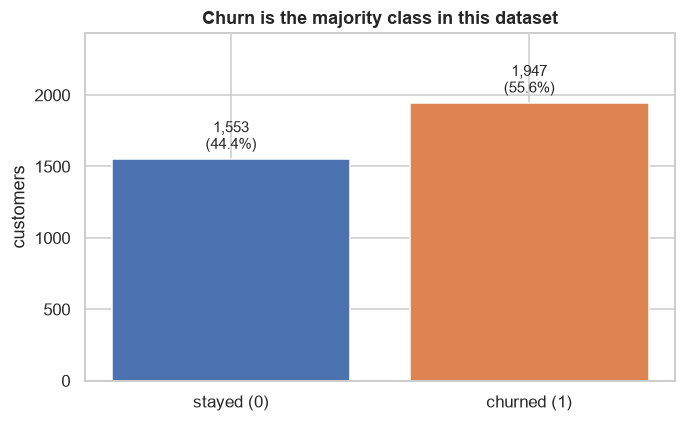

Churn rate: 0.556
Accuracy of the 'always churn' dummy model: 0.556


In [10]:
counts = raw["churn"].value_counts().sort_index()
labels = ["stayed (0)", "churned (1)"]
colors = ["#4C72B0", "#DD8452"]

fig, ax = plt.subplots(figsize=(6.4, 4))
bars = ax.bar(labels, counts.values, color=colors)
for bar, n in zip(bars, counts.values):
    ax.text(bar.get_x() + bar.get_width() / 2, n + 40, f"{n:,}\n({n / len(raw):.1%})",
            ha="center", va="bottom", fontsize=10)
ax.set_ylim(0, counts.max() * 1.25)
ax.set_ylabel("customers")
ax.set_title("Churn is the majority class in this dataset")
fig.tight_layout()
fig.savefig(FIG / "01_target_balance.png", bbox_inches="tight")
plt.show()

print(f"Churn rate: {raw['churn'].mean():.3f}")
print(f"Accuracy of the 'always churn' dummy model: {max(counts) / len(raw):.3f}")

**What it means.** The dataset is deliberately balanced toward churn (the real Telco benchmark is
about 26.5%). Two consequences follow:

1. **Report precision, recall and PR-AUC**, not accuracy. With a 5:1 cost ratio between a missed
   churner and a false alarm, the decision threshold matters more than the raw score.
2. **Treat the 55.6% base rate as a property of this file**, not of the business. Any estimate of
   real-world churn has to come from a representative sample.

**What to do.** Use PR-AUC / recall at a fixed budget as the headline metric, and always show the
dummy model next to the real one.

### Insight 2 — Contract length is the strongest lever the company controls

A month-to-month customer can leave at any time; a two-year customer has a reason to stay.
The gap is large, consistent, and it points at a concrete retention action.

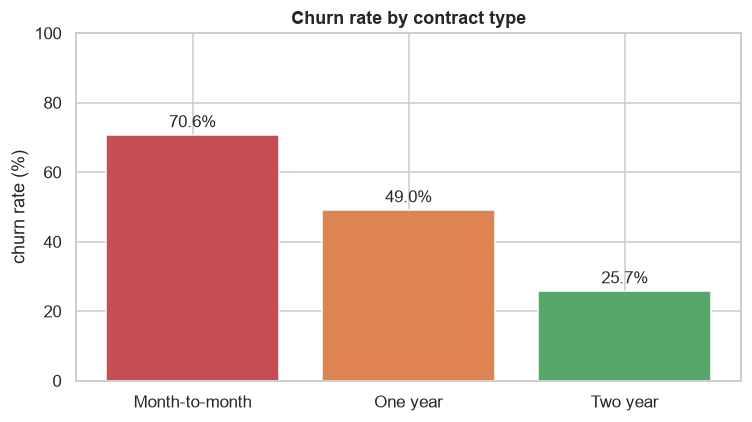

,customers,churn_pct
contract,,
Month-to-month,1937,70.6
One year,764,49.0
Two year,799,25.7


In [11]:
contract = (
    df.groupby("contract")["churn"]
    .agg(customers="size", churn_rate="mean")
    .sort_values("churn_rate", ascending=False)
)
contract["churn_pct"] = (contract["churn_rate"] * 100).round(1)

fig, ax = plt.subplots(figsize=(7, 4))
bars = ax.bar(contract.index, contract["churn_pct"], color=["#C44E52", "#DD8452", "#55A868"])
ax.bar_label(bars, fmt="%.1f%%", padding=3, fontsize=11)
ax.set_ylim(0, 100)
ax.set_ylabel("churn rate (%)")
ax.set_title("Churn rate by contract type")
ax.set_xlabel("")
fig.tight_layout()
fig.savefig(FIG / "04_contract_churn.png", bbox_inches="tight")
plt.show()
contract[["customers", "churn_pct"]]

In [12]:
combo = (
    df.groupby(["contract", "internet_service"])["churn"]
    .agg(customers="size", churn_rate="mean")
    .reset_index()
    .pivot(index="contract", columns="internet_service", values="churn_rate")
    .round(3)
)
combo.index.name = "contract / internet"
combo

internet_service,DSL,Fiber optic,No
contract / internet,,,
Month-to-month,0.641,0.824,0.566
One year,0.392,0.639,0.349
Two year,0.188,0.372,0.149


**What it means.** Month-to-month customers churn at **70.6%**, one-year customers at **49.0%** and
two-year customers at **25.7%** — a 45-point gap. Within contracts, fiber-optic customers are also
more likely to leave; the worst combination is **month-to-month + fiber optic (82.4%)**, the best is
**two-year + no internet (14.9%)**.

**What to do.** Price a contract-upgrade offer specifically for the month-to-month + fiber segment:
**860 customers at 82.4% churn** (fiber overall is 1,523 customers, 44% of the file). The data says
commitment is associated with much lower churn. This is a correlation, not proof of causation —
which is exactly why the next step should be a controlled A/B test.

### Insight 3 — The first year is the danger zone

Tenure is the strongest *legitimate* numeric signal (r = −0.33 with churn). Segmenting it makes the
pattern readable for non-technical stakeholders.

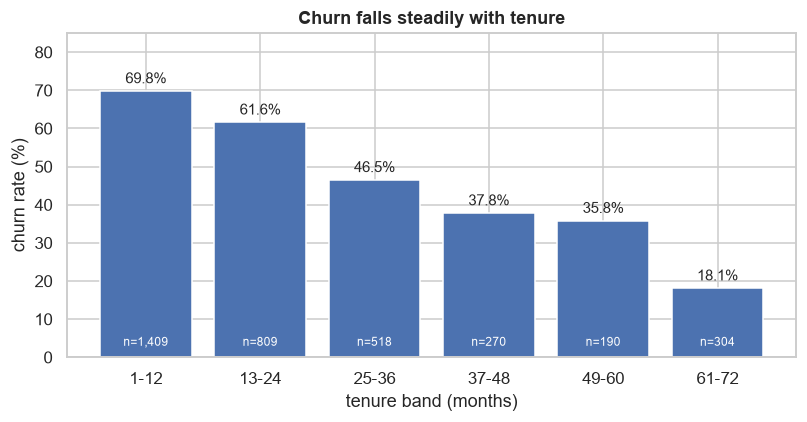

,customers,churn_pct
tenure_band,,
1-12,1409,69.8
13-24,809,61.6
25-36,518,46.5
37-48,270,37.8
49-60,190,35.8
61-72,304,18.1


In [13]:
tenure = (
    df.groupby("tenure_band", observed=False)["churn"]
    .agg(customers="size", churn_rate="mean")
)
tenure["churn_pct"] = (tenure["churn_rate"] * 100).round(1)

fig, ax = plt.subplots(figsize=(7.5, 4))
bars = ax.bar(tenure.index.astype(str), tenure["churn_pct"], color="#4C72B0")
ax.bar_label(bars, fmt="%.1f%%", padding=3, fontsize=10)
for i, n in enumerate(tenure["customers"]):
    ax.text(i, 3, f"n={n:,}", ha="center", fontsize=8, color="white")
ax.set_ylim(0, 85)
ax.set_ylabel("churn rate (%)")
ax.set_xlabel("tenure band (months)")
ax.set_title("Churn falls steadily with tenure")
fig.tight_layout()
fig.savefig(FIG / "05_tenure_churn.png", bbox_inches="tight")
plt.show()
tenure[["customers", "churn_pct"]]

**What it means.** **69.8%** of customers in their first 12 months churn, versus **18.1%** of those
who have stayed 5+ years. The relationship is monotonic across all six bands, which makes it
credible rather than a fluke of one bin.

**What to do.** Put onboarding and first-year check-ins at the top of the retention budget: the
same absolute improvement in churn rate saves more customers in the 1–12-month band than anywhere
else (it contains 1,409 of the 3,500 customers).

### Insight 4 — Support calls are an early-warning siren

Support calls are the clearest *behavioural* signal in the data: customers do not call because they
are happy. The question is how strong the escalation is.

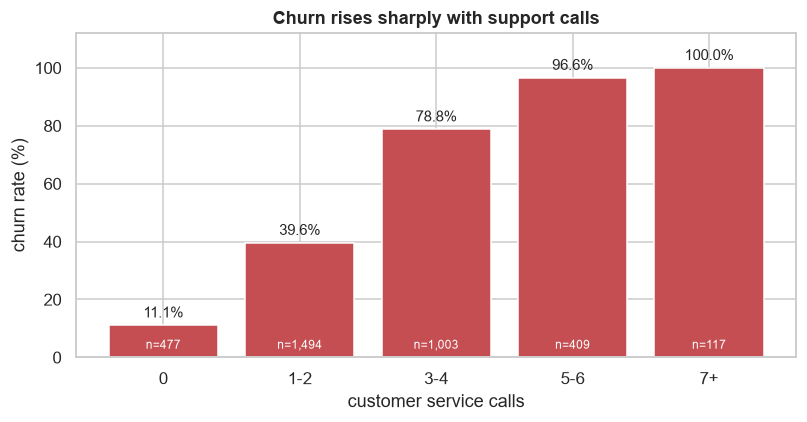

,customers,churn_pct
calls_band,,
0,477,11.1
1-2,1494,39.6
3-4,1003,78.8
5-6,409,96.6
7+,117,100.0


In [14]:
calls = (
    df.groupby("calls_band", observed=False)["churn"]
    .agg(customers="size", churn_rate="mean")
)
calls["churn_pct"] = (calls["churn_rate"] * 100).round(1)

fig, ax = plt.subplots(figsize=(7.5, 4))
bars = ax.bar(calls.index.astype(str), calls["churn_pct"], color="#C44E52")
ax.bar_label(bars, fmt="%.1f%%", padding=3, fontsize=10)
for i, n in enumerate(calls["customers"]):
    ax.text(i, 3, f"n={n:,}", ha="center", fontsize=8, color="white")
ax.set_ylim(0, 112)
ax.set_ylabel("churn rate (%)")
ax.set_xlabel("customer service calls")
ax.set_title("Churn rises sharply with support calls")
fig.tight_layout()
fig.savefig(FIG / "06_calls_churn.png", bbox_inches="tight")
plt.show()
calls[["customers", "churn_pct"]]

**What it means.** Churn goes from **11.1%** (zero calls) to **39.6%** (1–2), **78.8%** (3–4),
**96.6%** (5–6) and **100%** in the 7+ group (117 customers). The escalation is not subtle: after
three calls, churn is more likely than not.

*(The 35 missing call counts were filled with the median of 2 for this analysis, which slightly
enlarges the 1–2 band: 1,494 customers here versus 1,459 in the raw file. The pattern is unchanged.)*

**What to do.** Trigger a retention workflow after the **second** call, not after cancellation.
This is an operational lever with no price discount attached — it changes *when* the company acts,
not how much it spends.

### Insight 5 — Four columns leak the answer (and one is a derived column)

This is the data-quality finding that saves the modelling project. Some columns are recorded
*after* the customer has already decided to leave. They separate churn almost perfectly, so a model
using them scores ~100% in validation and is worthless in production.

In [15]:
leak_rows = []
for col in LEAKAGE:
    tmp = (
        raw.assign(value=raw[col].fillna("(missing)"))
        .groupby("value", dropna=False)["churn"]
        .agg(customers="size", churn_rate="mean")
        .sort_values("churn_rate")
    )
    leak_rows.append(
        {
            "column": col,
            "distinct values": len(tmp),
            "min churn rate": f"{tmp['churn_rate'].min():.1%}",
            "max churn rate": f"{tmp['churn_rate'].max():.1%}",
            "verdict": "LEAKAGE - recorded at/after exit",
        }
    )

pd.DataFrame(leak_rows).set_index("column")

,distinct values,min churn rate,max churn rate,verdict
column,,,,
cancellation_request,2,0.0%,100.0%,LEAKAGE - recorded at/after exit
last_interaction_status,7,0.0%,100.0%,LEAKAGE - recorded at/after exit
churn_risk_post_exit_code,2,0.0%,100.0%,LEAKAGE - recorded at/after exit
satisfaction_score,5,0.0%,100.0%,LEAKAGE - recorded at/after exit


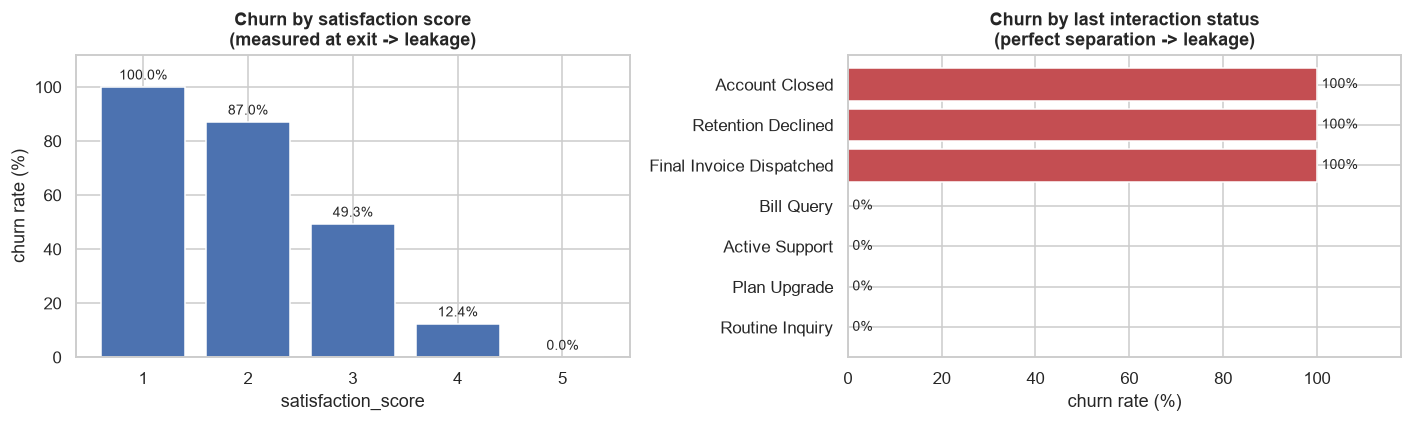

cancellation_request vs churn:
churn                    0     1   All
cancellation_request                  
(missing)             1553     0  1553
Recorded                 0  1947  1947
All                   1553  1947  3500


In [16]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

sat = raw.groupby("satisfaction_score")["churn"].mean().mul(100)
axes[0].bar(sat.index.astype(str), sat.values, color="#4C72B0")
axes[0].bar_label(axes[0].containers[0], fmt="%.1f%%", padding=3, fontsize=9)
axes[0].set_title("Churn by satisfaction score\n(measured at exit -> leakage)")
axes[0].set_xlabel("satisfaction_score")
axes[0].set_ylabel("churn rate (%)")
axes[0].set_ylim(0, 112)

status = (
    raw.groupby("last_interaction_status")["churn"].mean().mul(100).sort_values(ascending=False)
)
axes[1].barh(status.index[::-1], status.values[::-1], color="#C44E52")
axes[1].bar_label(axes[1].containers[0], fmt="%.0f%%", padding=3, fontsize=9)
axes[1].set_title("Churn by last interaction status\n(perfect separation -> leakage)")
axes[1].set_xlabel("churn rate (%)")
axes[1].set_xlim(0, 118)

fig.tight_layout()
fig.savefig(FIG / "07_leakage.png", bbox_inches="tight")
plt.show()

print("cancellation_request vs churn:")
print(pd.crosstab(raw["cancellation_request"].fillna("(missing)"), raw["churn"], margins=True).to_string())

**What it means.** Every one of these columns is a *post-outcome* variable:

| column | why it leaks |
|---|---|
| `cancellation_request` | `"Recorded"` exists only for churners; the 1,553 NaNs are exactly the customers who stayed |
| `last_interaction_status` | `"Account Closed"`, `"Retention Declined"`, `"Final Invoice Dispatched"` happen **because** the customer left |
| `churn_risk_post_exit_code` | `999` for churners, `100` for stayers — it is the target encoded twice |
| `satisfaction_score` | measured when the customer exits: 100% churn at score 1, 0% at score 5 |

There is also a **derived** column: `total_charges` is almost exactly
`monthly_charges × tenure_months` (r = 0.9995, median absolute difference $33.6). It is legitimate
at prediction time, but it duplicates information and destabilises linear models — keep it as a
convenience feature, or drop one of the two in a linear model.

**What to do.** Remove all four leakage columns before any modelling (as this notebook does), and
add a leakage check to every future dataset. If a model reports 99–100% accuracy on churn,
suspect leakage before celebrating.

---

## 5. Next steps

### Modelling plan

1. **Features:** the 14 legitimate columns left in `df` (contract, tenure, services, charges,
   payment method, flags). Drop `customer_id` and the four leakage columns.
2. **Split:** stratified 60/20/20 train/validation/test, fixed seed. There are no dates in this
   file, so a time-based split is not possible — say so explicitly instead of pretending.
3. **Baselines first:** majority class (55.6% accuracy, 0.556 churn recall but useless precision)
   and logistic regression. Then gradient boosting.
4. **Metric:** PR-AUC and recall at a fixed retention budget, with a cost-weighted threshold
   (missed churner = $500, false alarm = $100). Accuracy is not the decision metric.
5. **Calibration:** check the reliability curve; the threshold is only meaningful on calibrated
   probabilities.

### Data collection improvements

* Record `satisfaction_score` **during** the customer's life, not at exit (it is currently a label
  in disguise).
* Store a cancellation **reason** and the date of every interaction, so churn can be analysed over
  time instead of as a snapshot.
* Keep the call log, not just the call count: topic and resolution time are likely stronger signals
  than "number of calls".

### Experiments worth running

* **Contract upgrade offer** for month-to-month + fiber customers (the 82.4% churn segment).
* **Onboarding programme** for customers in months 1–3 (the 69.8% band).
* **Proactive callback** after the second support call (the 78.8% band).

### Reproduce this report

```bash
python generate_data.py                 # rebuilds data/telecom_churn.csv (same seed)
jupyter notebook eda_report.ipynb       # run all cells
```

**Data note.** `data/` is gitignored: the CSV is rebuilt from `generate_data.py`, so the repository
stays small and every number remains reproducible.

---

## Appendix — cleaning audit trail

| Check | Result |
|---|---|
| Rows before / after cleaning | 3,500 / 3,500 (no rows dropped) |
| Columns before / after cleaning | 23 / 22 (1 ID + 4 leakage removed, 2 flags + 2 bands added) |
| Missing values after cleaning | 0 |
| Duplicate rows | 0 |
| Target | unchanged (`churn`, 1,947 positives) |
| Leakage columns in modelling frame | 0 |

**Files produced by this notebook**

| File | Content |
|---|---|
| `figures/01_target_balance.png` | class balance and the dummy-model accuracy |
| `figures/02_missingness.png` | missing values per column |
| `figures/03_distributions.png` | numeric distributions |
| `figures/04_contract_churn.png` | churn by contract type |
| `figures/05_tenure_churn.png` | churn by tenure band |
| `figures/06_calls_churn.png` | churn by support-call band |
| `figures/07_leakage.png` | the two most obvious leakage patterns |